### **Импорты и загрузка данных**

Пути к данным указаны для запуска из папки `your-sollution`.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

In [2]:
SEED = 42

# np.load читает массивы из npz по обращению к ключу: prediction здесь не открываем.
with np.load('../dataset/task3_2/train.npz', allow_pickle=False) as train:
    images = train['images']

with np.load('../dataset/task3_2/test_features.npz', allow_pickle=False) as test:
    test_images = test['images']
    test_ids = test['image_id']

print('train:', images.shape, ' test_features:', test_images.shape)
print('Тип пикселей:', images.dtype, 'диапазон:', (images.min(), images.max()))
assert images.shape[1:] == test_images.shape[1:] == (28, 28, 3)
assert images.dtype == test_images.dtype == np.uint8
assert len(test_ids) == len(test_images) and len(np.unique(test_ids)) == len(test_ids)


train: (3600, 28, 28, 3)  test_features: (900, 28, 28, 3)
Тип пикселей: uint8 диапазон: (np.uint8(0), np.uint8(255))


### **Исходные изображения без меток**


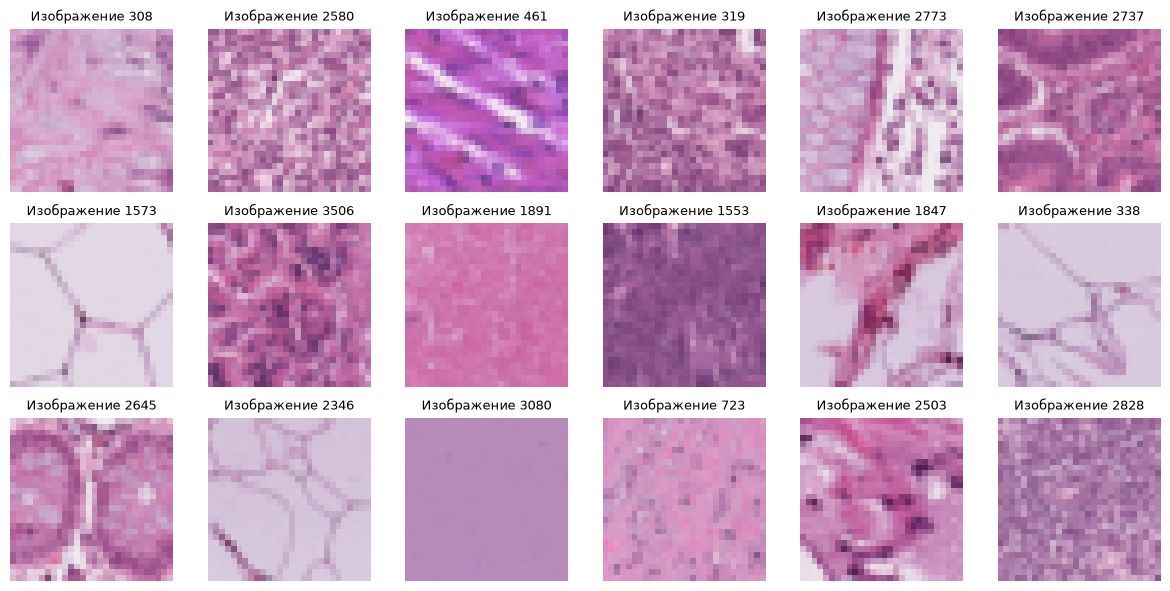

In [3]:
rng = np.random.default_rng(SEED)
example_idx = rng.choice(len(images), size=18, replace=False)
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for ax, idx in zip(axes.ravel(), example_idx):
    ax.imshow(images[idx])
    ax.set_title(f'Изображение {idx}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()


### **Распрямление и нормализация пикселей**

Каждое изображение превращаем в вектор из 28 × 28 × 3 = 2352 признаков
и делим на 255. Все признаки имеют одну шкалу; отдельный StandardScaler не нужен.
Общее масштабирование не меняет геометрию евклидовых расстояний.
Test обрабатываем той же формулой; статистики по нему не оцениваем.


In [4]:
X = images.reshape(len(images), -1).astype(np.float32) / 255.0
X_test = test_images.reshape(len(test_images), -1).astype(np.float32) / 255.0

assert np.isfinite(X).all() and np.isfinite(X_test).all()
print('Признаки train:', X.shape, ' test:', X_test.shape)
print('Диапазон после нормализации:', (X.min(), X.max()))


Признаки train: (3600, 2352)  test: (900, 2352)
Диапазон после нормализации: (np.float32(0.0), np.float32(1.0))


### **KMeans с девятью кластерами**

Берём k = 9 из постановки задания. Используем 20 инициализаций с seed = 42;
KMeans выбирает результат с минимальной суммой квадратов расстояний до центров.
Метки тканей и данные task3-1 в обучении и выборе параметров не участвуют.
Центры обучаем только на train; для test вызываем `predict` той же модели.


In [5]:
n_clusters = 9
kmeans = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED)
clusters = kmeans.fit_predict(X)
test_clusters = kmeans.predict(X_test)

print('Число итераций:', kmeans.n_iter_)
print('Inertia:', round(kmeans.inertia_, 2))
cluster_sizes = pd.DataFrame({
    'train': np.bincount(clusters, minlength=n_clusters),
    'test_features': np.bincount(test_clusters, minlength=n_clusters),
}, index=pd.Index(range(n_clusters), name='кластер'))
cluster_sizes


Число итераций: 39
Inertia: 76776.91


,train,test_features
кластер,,
0,10,3
1,129,27
2,798,195
3,221,62
4,864,212
5,286,67
6,345,98
7,353,86
8,594,150


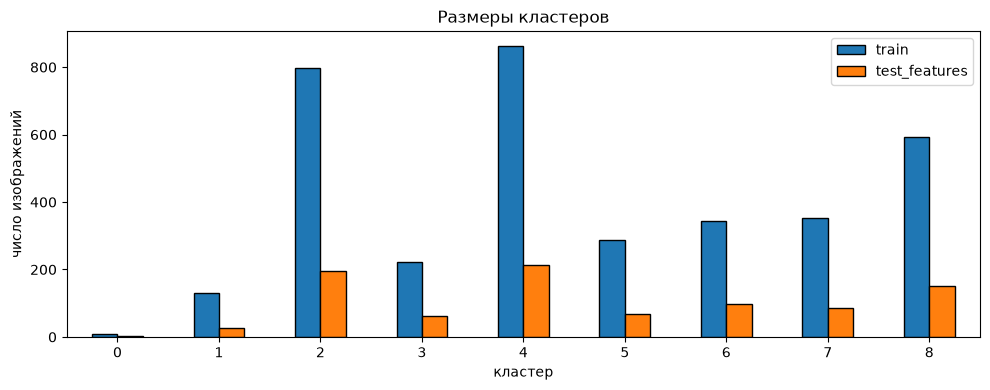

In [6]:
cluster_sizes.plot.bar(figsize=(10, 4), edgecolor='black', rot=0)
plt.ylabel('число изображений')
plt.title('Размеры кластеров')
plt.tight_layout()
plt.show()


### **Silhouette без истинных меток**

Считаем silhouette в исходном пространстве 2352 признаков с евклидовой метрикой
на случайной подвыборке из 2000 обучающих изображений без возвращения (seed = 42).
Это оценка на подвыборке, а не на всех парах изображений; метки тканей не нужны.


In [7]:
sample_size = min(2000, len(X))
silhouette = silhouette_score(
    X, clusters, metric='euclidean', sample_size=sample_size, random_state=SEED,
)
print(f'Silhouette = {silhouette:.3f}, подвыборка: {sample_size} из {len(X)}')


Silhouette = 0.090, подвыборка: 2000 из 3600


### **Чтение меток только для оценки и интерпретации**

Кластеризация завершена, назначения train и test уже получены.
Теперь читаем открытые метки и считаем ARI и NMI на всех изображениях train.
Эти метрики не зависят от перестановки номеров кластеров;
номер кластера не является предсказанным классом ткани.


In [8]:
with np.load('../dataset/task3_2/train.npz', allow_pickle=False) as train:
    y = train['prediction'].reshape(-1)
    label_names = train['label_names']

class_ids = np.arange(9)
class_codes = ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
assert len(y) == len(images) and np.array_equal(np.unique(y), class_ids)
ari = adjusted_rand_score(y, clusters)
nmi = normalized_mutual_info_score(y, clusters)

pd.DataFrame({'ARI': [ari], 'NMI': [nmi], 'silhouette': [silhouette]}, index=['KMeans']).round(3)


,ARI,NMI,silhouette
KMeans,0.15,0.284,0.09


In [9]:
pd.DataFrame({
    'класс': class_ids, 'код': class_codes, 'ткань': label_names,
    'число изображений': np.bincount(y, minlength=9),
})


,класс,код,ткань,число изображений
0,0,ADI,adipose,375
1,1,BACK,background,381
2,2,DEB,debris,415
3,3,LYM,lymphocytes,416
4,4,MUC,mucus,320
5,5,MUS,smooth muscle,487
6,6,NORM,normal colon mucosa,315
7,7,STR,cancer-associated stroma,376
8,8,TUM,colorectal adenocarcinoma epithelium,515


### **Проекции PCA и t-SNE**

Для визуализации обучаем PCA с 50 компонентами только на train, без меток.
Из этих компонент строим t-SNE на случайной подвыборке из 2000 изображений
(seed = 42); для сопоставимости в PCA-графиках используем те же изображения.
В каждой паре графиков координаты одинаковы, меняется только окраска.
KMeans обучен на исходных пикселях; эти проекции не используются для назначения кластеров.


In [10]:
pca = PCA(n_components=50, svd_solver='randomized', random_state=SEED)
X_pca = pca.fit_transform(X)
print('Дисперсия в первых двух компонентах:', round(pca.explained_variance_ratio_[:2].sum(), 3))
print('Дисперсия в 50 компонентах:', round(pca.explained_variance_ratio_.sum(), 3))

rng = np.random.default_rng(SEED)
plot_idx = rng.choice(len(X), size=min(2000, len(X)), replace=False)
points_pca = X_pca[plot_idx, :2]
points_tsne = TSNE(
    n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED,
).fit_transform(X_pca[plot_idx])


Дисперсия в первых двух компонентах: 0.578
Дисперсия в 50 компонентах: 0.797


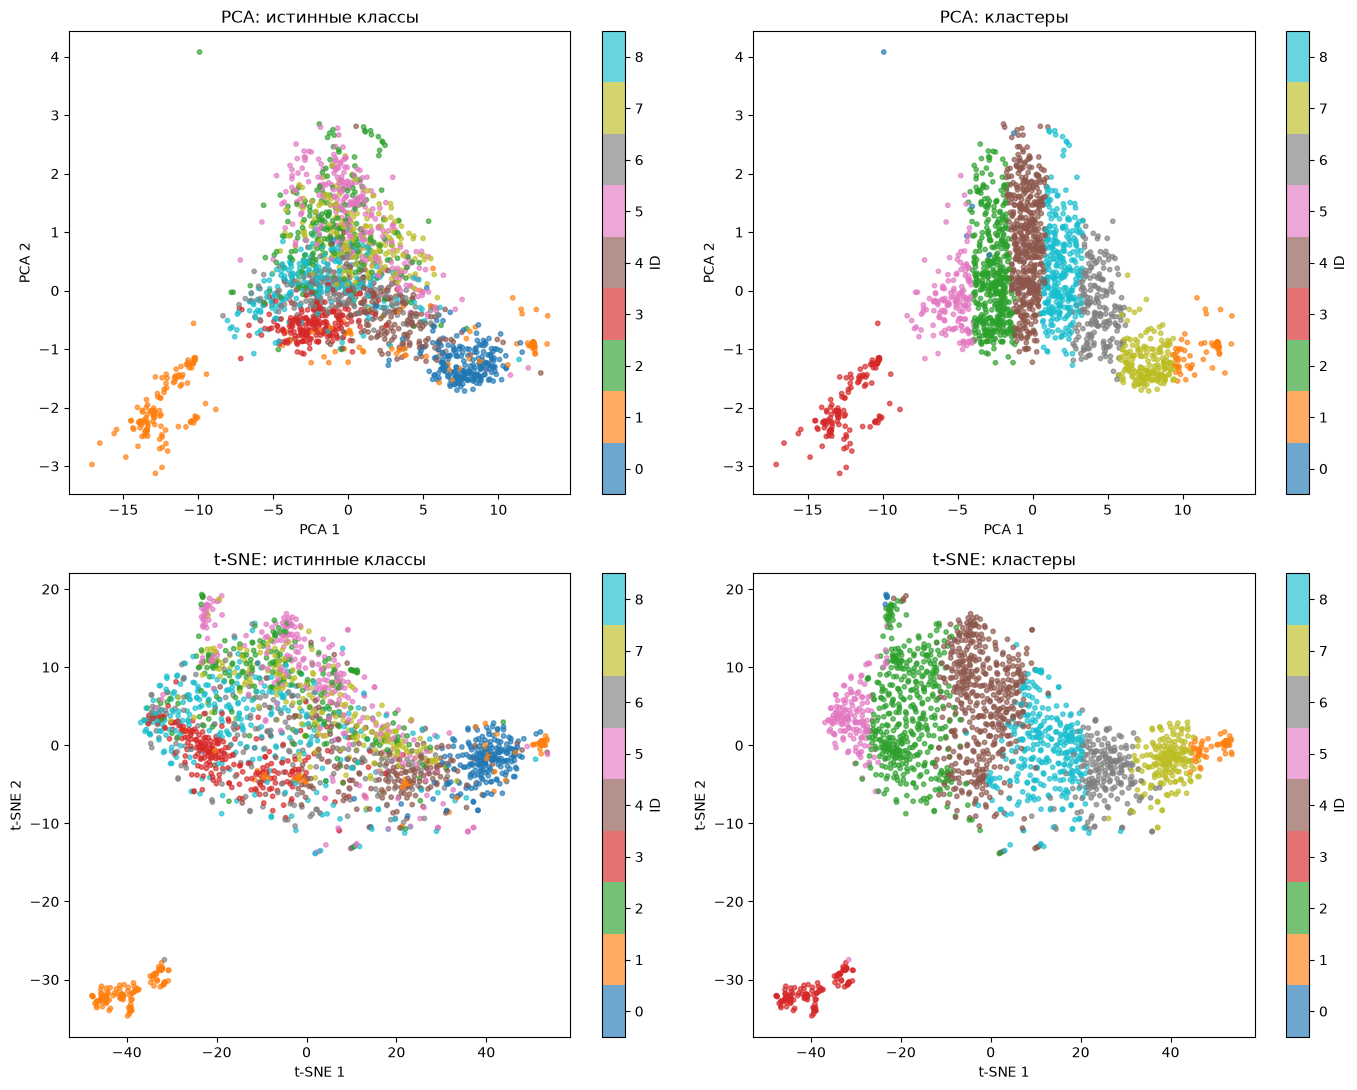

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for row, (points, name) in enumerate([(points_pca, 'PCA'), (points_tsne, 't-SNE')]):
    for col, (color_labels, title) in enumerate([(y[plot_idx], 'истинные классы'), (clusters[plot_idx], 'кластеры')]):
        ax = axes[row, col]
        scatter = ax.scatter(
            points[:, 0], points[:, 1], c=color_labels, cmap=plt.get_cmap('tab10', 9),
            vmin=-0.5, vmax=8.5, s=10, alpha=0.65,
        )
        ax.set_title(f'{name}: {title}')
        ax.set_xlabel(f'{name} 1')
        ax.set_ylabel(f'{name} 2')
        fig.colorbar(scatter, ax=ax, ticks=class_ids, label='ID')
plt.tight_layout()
plt.show()


### **Центроиды кластеров**

Центры в пространстве пикселей можно вернуть в форму 28 × 28 × 3.
Это усреднённые изображения, поэтому мелкие детали в них размыты.


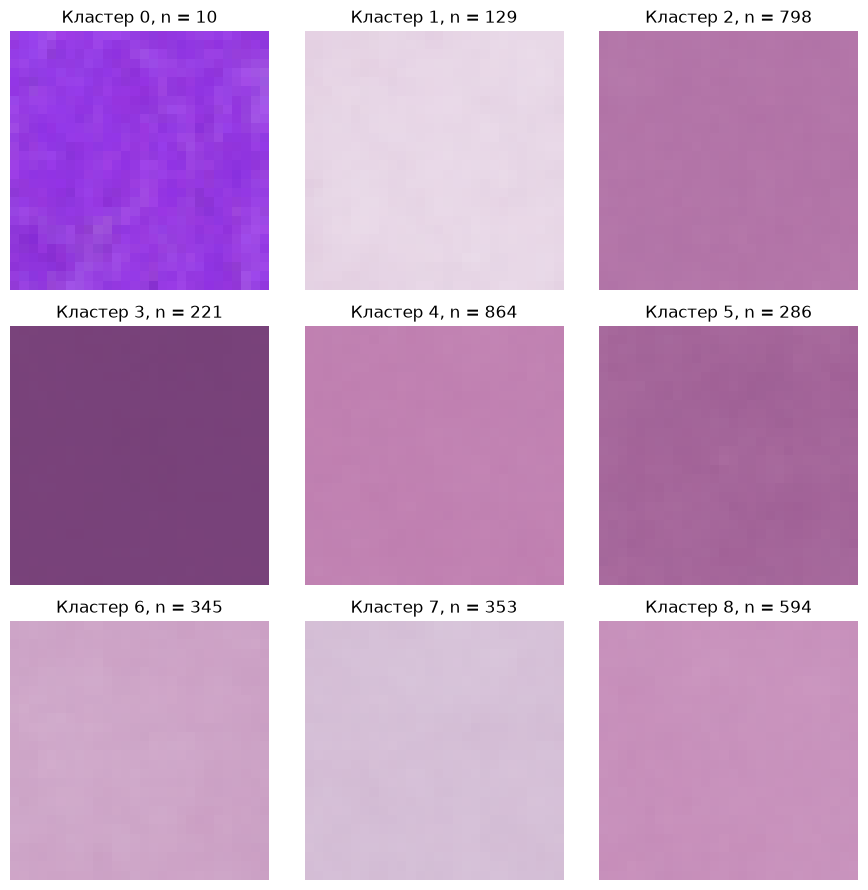

In [12]:
centroids = kmeans.cluster_centers_.reshape(n_clusters, 28, 28, 3)
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(np.clip(centroids[k], 0, 1))
    ax.set_title(f'Кластер {k}, n = {(clusters == k).sum()}')
    ax.axis('off')
plt.tight_layout()
plt.show()


### **Таблица «класс–кластер»**


In [13]:
ct = pd.crosstab(
    pd.Series(y, name='класс'), pd.Series(clusters, name='кластер'),
).reindex(index=class_ids, columns=range(n_clusters), fill_value=0)
ct.index = pd.Index(class_codes, name='класс')
ct


кластер,0,1,2,3,4,5,6,7,8
класс,,,,,,,,,
ADI,0,51,0,0,1,0,31,288,4
BACK,0,67,12,221,17,8,25,24,7
DEB,10,3,121,0,142,28,21,5,85
LYM,0,0,234,0,96,60,2,1,23
MUC,0,4,14,0,55,2,111,23,111
MUS,0,3,78,0,201,13,69,8,115
NORM,0,0,91,0,81,44,28,3,68
STR,0,0,65,0,147,7,39,0,118
TUM,0,1,183,0,124,124,19,1,63


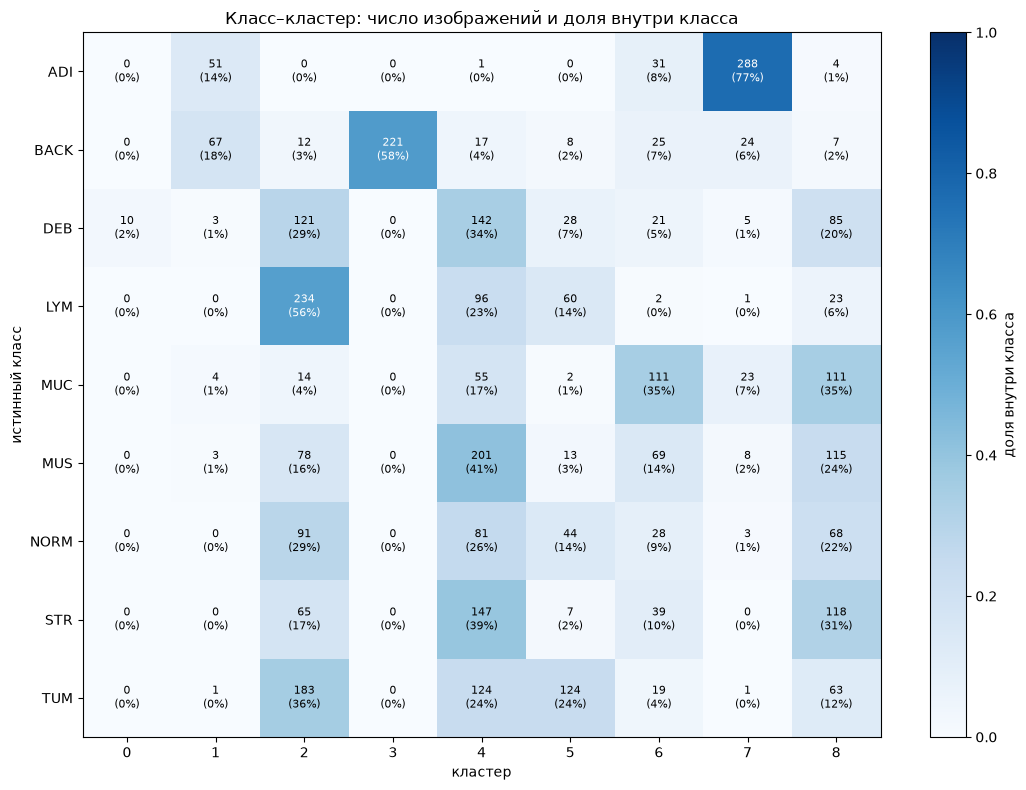

In [14]:
# Нормируем по строкам: как изображения каждого истинного класса распределены по кластерам.
class_shares = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(class_shares, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(len(class_codes)):
    for k in range(n_clusters):
        share = class_shares.iloc[i, k]
        ax.text(k, i, f'{ct.iloc[i, k]}\n({share:.0%})', ha='center', va='center',
                color='white' if share > 0.5 else 'black', fontsize=8)
ax.set_xticks(range(n_clusters))
ax.set_yticks(class_ids, class_codes)
ax.set_xlabel('кластер')
ax.set_ylabel('истинный класс')
ax.set_title('Класс–кластер: число изображений и доля внутри класса')
fig.colorbar(im, ax=ax, label='доля внутри класса')
plt.tight_layout()
plt.show()


### **Состав кластеров по истинным классам**

Здесь нормируем уже внутри каждого кластера: каждый столбец суммируется в 100%.
Это помогает отличать однородные группы от смешанных, не меняя обученную модель.


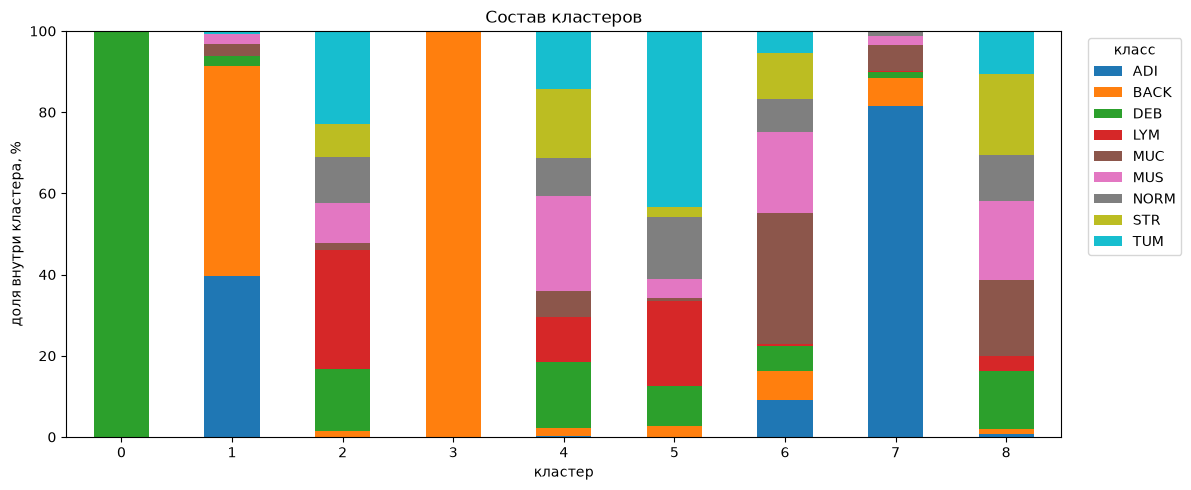

In [15]:
cluster_shares = ct.div(ct.sum(axis=0), axis=1) * 100
cluster_shares.T.plot.bar(stacked=True, figsize=(12, 5), colormap='tab10', rot=0)
plt.xlabel('кластер')
plt.ylabel('доля внутри кластера, %')
plt.title('Состав кластеров')
plt.legend(title='класс', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [16]:
cluster_summary = pd.DataFrame({
    'число изображений': ct.sum(axis=0),
    'доминирующий класс': ct.idxmax(axis=0),
    'его доля': ct.max(axis=0) / ct.sum(axis=0),
})
cluster_summary.round(3)


,число изображений,доминирующий класс,его доля
кластер,,,
0,10,DEB,1.000
1,129,BACK,0.519
2,798,LYM,0.293
3,221,BACK,1.000
4,864,MUS,0.233
5,286,TUM,0.434
6,345,MUC,0.322
7,353,ADI,0.816
8,594,STR,0.199


### **Типичные и случайные изображения кластеров**

В каждой строке слева — два изображения, ближайших к центру своего кластера,
справа — три случайных изображения из остальных. Подписи тканей нужны только для интерпретации.


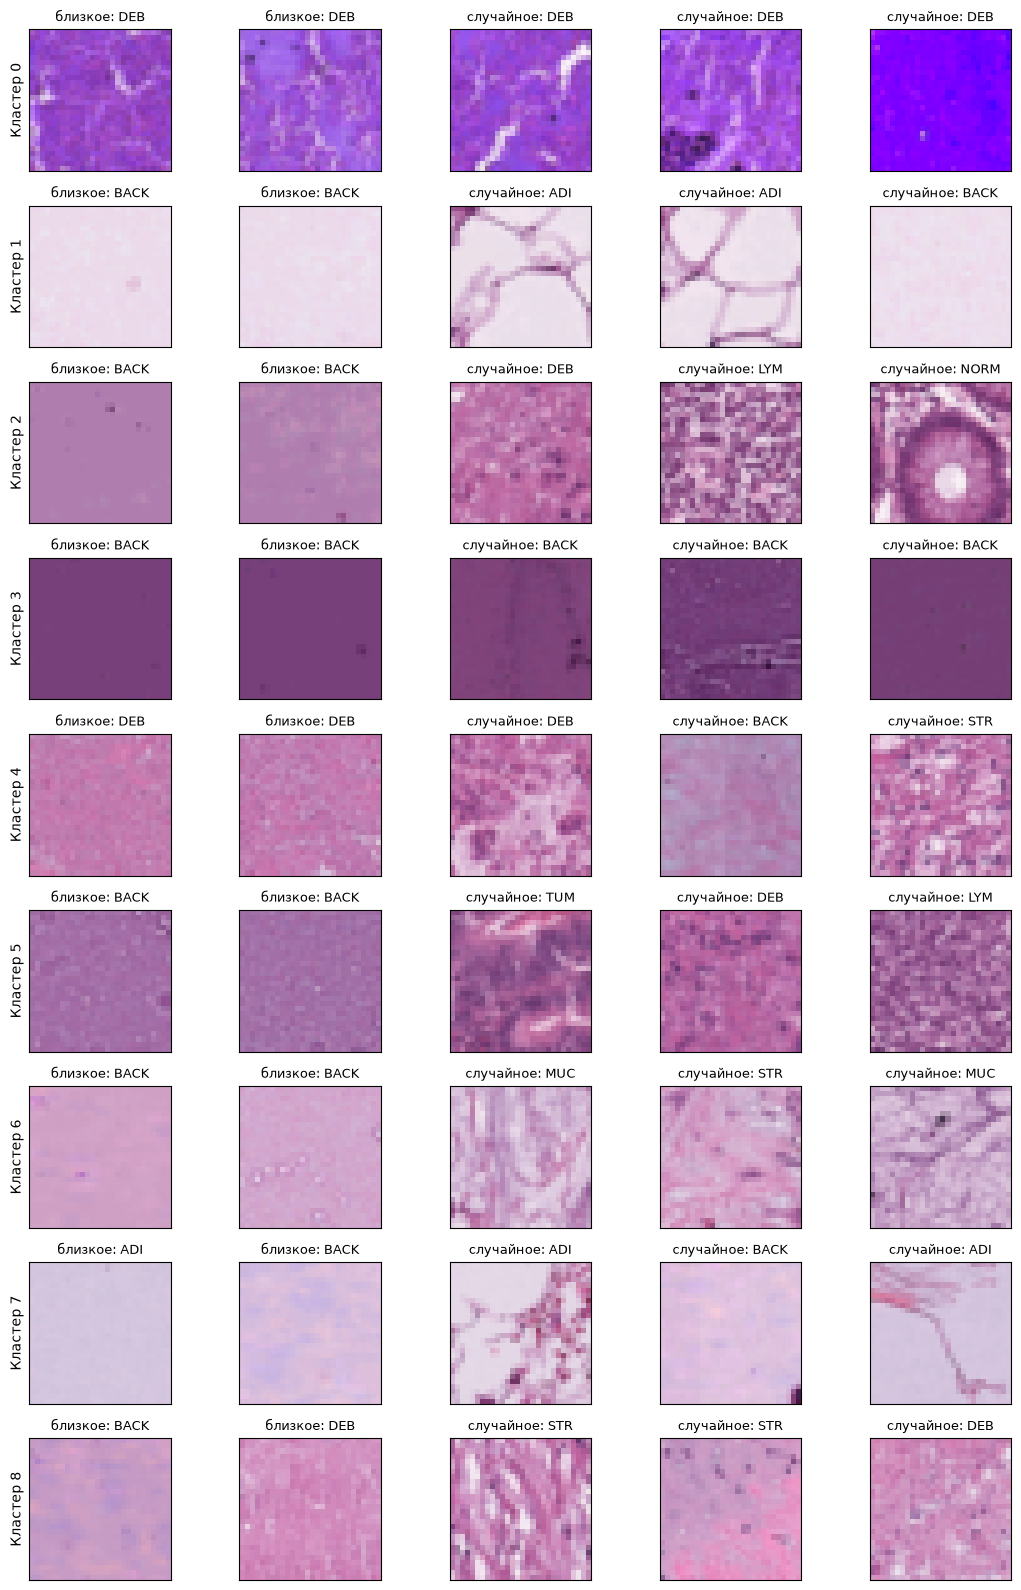

In [17]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(n_clusters, 5, figsize=(11, 16))
for k in range(n_clusters):
    indices = np.flatnonzero(clusters == k)
    distances = np.linalg.norm(X[indices] - kmeans.cluster_centers_[k], axis=1)
    nearest = indices[np.argsort(distances)[:2]]
    remaining = np.setdiff1d(indices, nearest)
    random_indices = rng.choice(remaining, size=min(3, len(remaining)), replace=False)
    selected = np.concatenate([nearest, random_indices])
    for ax in axes[k]:
        ax.set_xticks([])
        ax.set_yticks([])
    for col, idx in enumerate(selected):
        axes[k, col].imshow(images[idx])
        kind = 'близкое' if col < len(nearest) else 'случайное'
        axes[k, col].set_title(f'{kind}: {class_codes[y[idx]]}', fontsize=9)
    axes[k, 0].set_ylabel(f'Кластер {k}')
plt.tight_layout()
plt.show()


### **Назначения для test_features.npz**

Используем назначения, полученные сразу после обучения KMeans, до чтения меток.
Номера кластеров не переименовываем в классы тканей.


In [18]:
submission = pd.DataFrame({
    'image_id': test_ids,
    'prediction': test_clusters.astype(np.int64),
})
submission.head()


,image_id,prediction
0,20,2
1,48,7
2,318,2
3,319,4
4,486,7


In [19]:
submission['prediction'].value_counts().sort_index()


prediction
0      3
1     27
2    195
3     62
4    212
5     67
6     98
7     86
8    150
Name: count, dtype: int64

### **Сохранение в outputs/task3_2_predictions.csv**


In [ ]:
submission.to_csv('../outputs/task3_2_predictions.csv', index=False)
print('Файл сохранён: ../outputs/task3_2_predictions.csv, строк:', len(submission))


### **Описание решения**

1. **Данные.** 3600 обучающих и 900 отложенных RGB-изображений 28 × 28. Изображения распрямлены в 2352 признака, пиксели переведены в [0, 1]. Масштабирование одинаковое для train и test.
2. **Модель.** KMeans, k = 9 по условию, 20 инициализаций, seed = 42. Обучение только на train; test получает кластеры через `predict`. Метки тканей прочитаны после обучения и получения назначений test, в выборе признаков и параметров не участвуют.
3. **Метрики на train.** ARI = 0.150, NMI = 0.284. Silhouette = 0.090 в исходном пространстве пикселей на случайных 2000 изображениях без возвращения (seed = 42). Кластеры слабо разделены и лишь частично соответствуют тканям.
4. **Визуализации.** PCA и t-SNE показаны на одних и тех же 2000 изображениях с двумя вариантами окраски. Две компоненты PCA объясняют 57.8% дисперсии, 50 — 79.7%. Построены центроиды, таблица «класс–кластер», состав кластеров, близкие к центрам и случайные примеры.
5. **Интерпретация.** Кластер 3 состоит из 221 изображения фона (58% всего BACK). В кластере 7 — 288 изображений жировой ткани из 353 (81.6% кластера и 76.8% ADI). Кластер 0 содержит всего 10 изображений DEB; его однородность не означает, что весь класс найден. Остальные крупные группы смешанные: в самом большом кластере 4 (864 изображения) даже доминирующий MUS занимает лишь 23.3%.
6. **Ограничения.** Расстояния между сырыми пикселями чувствительны к цвету, яркости, сдвигам и ориентации; текстура тканей явно не моделируется. Низкие ARI и silhouette согласуются с этим ограничением. Метрики описывают обучающую выборку, качество на отложенных изображениях без меток неизвестно.